### Model Validation Report
| Field | Entry |
|---|---|
| Model name| Portfolio Value at Risk (VaR) Estimation: GARCH-Monte Carlo Simulation for EUR/USD|
| Model developer| Nikhil Srivastava | 
| Model validator| Joshua Sanchez |
| Model version | Version 1 |
| Dates for Model Creation | September 23, 2026 - October 8, 2026|
| Date of validation| October 29, 2026 - November 8, 2026 |
| Overall conclusion |Approved with conditions|

#### *Executive Summary*
This Value at Risk model estimates 1-day VaR and expected shortfall for a EUR/USD spot position by fitting a GARCH(1,1) volatility model with Student t shocks and simulating 100,000 Monte Carlo outcomes. The model was replicated without differences, no data leakage was found, and independent testing on a stress window (March 2020 to August 2021) and a forward window (October 2026) found exception counts consistent with the stated confidence levels, so the model is approved with conditions. The most important findings are that the documented 95% VaR metric is not computed in the simulation, the FRTB compliance claim is overstated, a simple EWMA benchmark matched or beat GARCH, and the monitoring plan lacks usable trigger levels.

| Severity | Number of findings |
|---|---|
| High |0 |
| Medium |4|
| Low | 6|


# *i. Scope of Review*
Materials reviewed: Version 1 of the EUR/USD GARCH Monte Carlo Value at Risk model, consisting of the developer’s documentation (purpose, scope, model outline, assumptions, limitations, and monitoring plan) and the accompanying Python notebook containing the code. The data are daily EUR/USD closing prices downloaded from Yahoo Finance using the yfinance package, with a requested window from September 21, 2021 to September 21, 2026. This data contains 1,299 daily closing prices.

Not tested: Alternative GARCH specifications (for example, GJR GARCH or EGARCH) were not tested as replacements for the developer’s model. GARCH(1,1) is a widely used baseline for VaR, and the purpose of this review is to assess the developer’s chosen specification against its stated scope, not to select a different model. Rolling window stability and lookback sensitivity tests were not performed because of time constraints. Parameter stability was assessed only by comparing training and full sample estimates (alpha 0.030 and 0.043, beta 0.965 and 0.952).

# *ii. Purpose, Business Context and Intended Use*

### Developer Section
#### Purpose
Value at Risk (VaR) is a standard risk-management metric used across modern banking institutions to quantify the potential financial loss of an asset or portfolio over a specified time horizon for a given confidence level. Foreign exchange (FX) markets are characterized by time-varying volatility, dynamic variance clustering, and heavy-tailed yield distributions, making traditional static variance assumptions (such as standard normal distribution models) inadequate.

This project develops an advanced market risk measurement framework for a **EUR/USD foreign exchange portfolio**. The framework combines a **Generalized Autoregressive Conditional Heteroskedasticity (GARCH(1,1))** model to capture time-varying volatility dynamics with a **Monte Carlo Simulation** methodology to project potential portfolio loss distributions over a specified horizon. Using historical EUR/USD daily closing price data from **2021 through 2026**, this project evaluates market exposure to support daily risk management and capital reserve requirements.

#### Business Context
For a bank trading desk holding currency positions in EUR/USD, sharp movements driven by macroeconomic developments (e.g., ECB/Federal Reserve rate policy shifts, geopolitical shocks) create significant market risk. Implementing a hybrid dynamic VaR framework using **GARCH + Monte Carlo** solves this by:
* Dynamically updating risk estimates based on current market volatility regimes.
* Simulating thousands of forward return paths to capture complex tail outcomes accurately.
* Supporting compliance with Basel Committee market risk standards (e.g., Fundamental Review of the Trading Book - FRTB)

#### Intended Use
* **Underlying Asset Class:** Foreign Exchange (FX).
* **Target Currency Pair:** EUR/USD (spot rates).
* **Data Horizon:** Daily closing prices from **January 2021 to September 2026**.
* **Risk Metric:** Value at Risk (VaR) at **95%** and **99%** confidence levels.
* **Holding Horizon:** 1-day forward (scalable to 10-day using standard square-root time rules or multi-step simulation).
* **Out of Scope:** Multi-asset cross-currency portfolios, interest rate differentials (carry trade risk), options/derivatives pricing models, and intra-day high-frequency trading dynamics.

### Validator Response
The business purpose is clearly stated, although it names two uses (daily risk management and capital reserve requirements) without identifying the primary one. The intended use is appropriate, and the developer lists examples that are out of scope. Gaps are the data horizon (F1), the 95% VaR metric (F2), the FRTB claim (F3), and the undocumented position direction and notional, with formulas implying a long EUR position (F10).

# *iii. Data Review*
Data is from Yahoo Finance using the 'yfinance' package, tracking daily EUR/USD closing prices (ticker EURUSD=X) using unadjusted closes. The window is from September 21, 2021 to September 21, 2026. This data contains 1,299 daily closing prices.
Train/Test Split follows: 
Train: 1038 obs  (2021-09-22 to 2025-09-17)
Test : 260 obs  (2025-09-18 to 2026-09-18)

Validator data checks found no missing closes, duplicate dates, non positive prices, or weekend rows. The largest absolute return (2.75% on April 11, 2025) agrees with the developer’s reported maximum. The only scaling is multiplication by a fixed constant (100) to express returns in percent, which is not fitted to data, and there is no missing value filling or capping. No leakage was found; the only input is the close price, converted to returns, so no feature depends on future information.

# *iv. Conceptual Soundness*
### Developer Section
## iv. Model Outline and Assumptions

### 1. Data Transformation (Log Returns)
Given daily spot price sequence $P_t$, simple returns are transformed into logarithmic returns $r_t$ to enforce time-additivity:

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

### 2. GARCH(1,1) Volatility Model
To capture volatility clustering, the dynamic conditional variance $\sigma_t^2$ is modeled as:

$$r_t = \mu + \epsilon_t, \quad \text{where } \epsilon_t = \sigma_t z_t \quad \text{and } z_t \sim \text{i.i.d. } \mathcal{N}(0, 1) \text{ or } t(\nu)$$

$$\sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2$$

Where:
* $\omega > 0$: Baseline constant variance.
* $\alpha \ge 0$: Reaction to recent market shocks (ARCH term).
* $\beta \ge 0$: Persistence of past volatility (GARCH term).
* Stationarity constraint: $\alpha + \beta < 1$.

### 3. Monte Carlo Simulation Engine
1. Estimate $\hat{\mu}, \hat{\omega}, \hat{\alpha}, \hat{\beta}$ from historical EUR/USD returns (2021–2026).
2. Extract the current spot price $P_T$ and the predicted baseline conditional volatility $\sigma_{T+1}$.
3. Draw $N$ standard random shocks $z_i \sim \mathcal{D}(0,1)$ (e.g., $N = 100,000$ iterations).
4. Simulate forward 1-day returns:

$$r_{T+1, i} = \hat{\mu} + \sigma_{T+1} z_i$$

5. Compute simulated portfolio value outcomes $V_{T+1, i} = V_T \cdot \exp(r_{T+1, i})$.
6. Value at Risk (VaR) at confidence level $1 - \alpha$ is the $\alpha$-quantile of simulated losses:

$$\text{VaR}_{\alpha} = V_T - \text{Percentile}\left(\{V_{T+1, i}\}_{i=1}^N, \alpha \times 100\right)$$

### Model Assumptions
1. **Stationarity:** The underlying process driving conditional parameters remains stationary over the calibration window.
2. **Distributional Structure:** Innovations $z_t$ are assume to follow a specified distribution (Standard Normal or Student’s $t$-distribution for heavy tails).
3. **No Liquidity Constraints:** Positions can be liquidated instantly at the prevailing market closing price without market impact.


| Assumption | How tested | Result | Holds? |
|---|---|---|---|
| Stationarity of returns | ADF and KPSS on returns | ADF statistic of negative 12.94 (p below 0.001), KPSS p-value at or above 0.10 | Yes |
| Alpha plus beta below 1 | GARCH fit |volatility persistence parameter of  0.995, very close to 1| Yes|
|Distributional Structure | Jarque-Bera and BIC|Normal rejected (p below 0.001), BIC 1,432 (t) vs 1,470 (Normal)|Yes for Student t|
|ARCH Effects|Ljung-Box on squared returns, ARCH-LM|both tests give p below 0.001, so constant variance is rejected, and volatility clustering is present|Yes|
|Constant Mean Equation is sufficient|Ljung-Box on returns|Ljung Box p value for returns is 0.0526, just above 0.05, and the estimated mean is near zero.|Yes|
| No liquidity constraints | Not tested | No volume or spread data in the dataset | Not tested |


Method appropriateness: GARCH(1,1) with Student t shocks and Monte Carlo simulation is appropriate for a single factor, linear EUR/USD spot position at a 1-day horizon. Volatility clustering is confirmed in the data (ARCH LM and Ljung-Box on squared returns both reject constant variance at p below 0.001), and the Normal assumption is rejected (Jarque-Bera p-value below 0.001, excess kurtosis of 1.97).

Alternatives: The notebook benchmarks EWMA and constant volatility and cross-checks against historical simulation, but this is not reflected in the documentation. The rejection of Normal innovations is well supported (BIC of 1,432 for Student t versus 1,470 for Normal). The documentation does not mention alternatives such as EWMA, constant volatility, or asymmetric GARCH variants, nor give reasons for rejecting them.



# *v. Replication*

| Reported metric | Developer's value | Replicated value | Match? |
|---|---|---|---|
| Price rows and return rows | 1,299 and 1,298 | 1,299 and 1,298 | Yes |
| Train and test observations | 1,038 and 260 | 1,038 and 260 | Yes |
| Selected distribution, nu | Student t, 6.49 | Student t, 6.49 | Yes |
| BIC, Student t vs Normal | 1,432.05 vs 1,469.99 | 1,432.05 vs 1,469.99 | Yes |
| Alpha, beta (training fit) | 0.0296, 0.9654 | 0.0296, 0.9654 | Yes |
| Next day volatility forecast | 0.3173% | 0.3173% | Yes |
| 1 day 99% VaR, Monte Carlo | \$0.8206 |  \$0.8206 | Yes |
| 1 day 99% expected shortfall | \$1.0262 |  \$1.0262 | Yes |
| 10 day 99% VaR, full path | \$2.556 | \$2.556 | Yes |
| 1% breaches, GARCH t (Kupiec p) | 0 (0.0222) | 0 (0.0222) | Yes |
| 5% breaches, GARCH t (Kupiec p) | 8 (0.1267) | 8 (0.1267) | Yes |

The model was replicated from the GitHub repository and the documentation without help from the developer. All code ran without errors, and every reported metric above was reproduced. Steps that were underspecified: package installation commands are commented out with no stated versions. 

# *vi. Independent Testing*

The developer’s model was run with parameters frozen at their training values (estimated on September 22, 2021 to September 17, 2025) on two windows not used in estimation: a stress window from March 1, 2020 to August 31, 2021 and a forward window from October 1 to October 31, 2026. A warm up from January 2019 let the volatility filter settle before scoring the stress window; the developer’s return history through September 18, 2026 served as the warm-up for the forward window. EWMA (lambda 0.94) and constant training volatility were included as benchmarks, using the same Student t quantile as GARCH. The parameters were estimated on later data, so the stress test is out of sample but not a real-time test

Results: In the stress window, GARCH produced 3 exceptions at the 1% level (3.92 expected) and 14 at the 5% level (19.6 expected), and was not rejected by the Kupiec or conditional coverage tests. The Basel traffic light for the worst 250-day stretch was green (2 exceptions). The largest loss, negative 2.81% on March 20, 2020, exceeded the 1% threshold by about 2.1 times. In the forward window, GARCH had 0 exceptions at 1% (0.22 expected) and 1 at 5% (1.1 expected). Average forecast volatility (0.338%) was about 20% above realized volatility (0.282%). Rolling window stability and lookback sensitivity tests were not performed because of time constraints. Parameter stability was assessed only by comparing training and full sample estimates (alpha 0.030 and 0.043, beta 0.965 and 0.952).

Conclusion and limitations: Exception counts were consistent with the stated confidence levels in both windows. GARCH tended to be slightly conservative in calm periods and adapted to shocks only after the first large loss. The forward window is too short to be informative, and the stress window contains a single episode. 

| Window | Level | Model | Breaches (expected) | Kupiec p | Cond. coverage p |
|---|---|---|---|---|---|
| Stress | 1% | GARCH t (frozen) | 3 (3.92) | 0.626 | 0.868 |
| Stress | 1% | EWMA | 4 (3.92) | 0.968 | 0.959 |
| Stress | 5% | GARCH t (frozen) | 14 (19.6) | 0.172 | 0.319 |
| Stress | 5% | EWMA | 22 (19.6) | 0.585 | 0.838 |
| Forward | 1% | GARCH t (frozen) | 0 (0.22) | 0.506 | 0.802 |
| Forward | 1% | EWMA | 1 (0.22) | 0.221 | 0.450 |
| Forward | 5% | GARCH t (frozen) | 1 (1.1) | 0.921 | 0.947 |
| Forward | 5% | EWMA | 1 (1.1) | 0.921 | 0.947 |

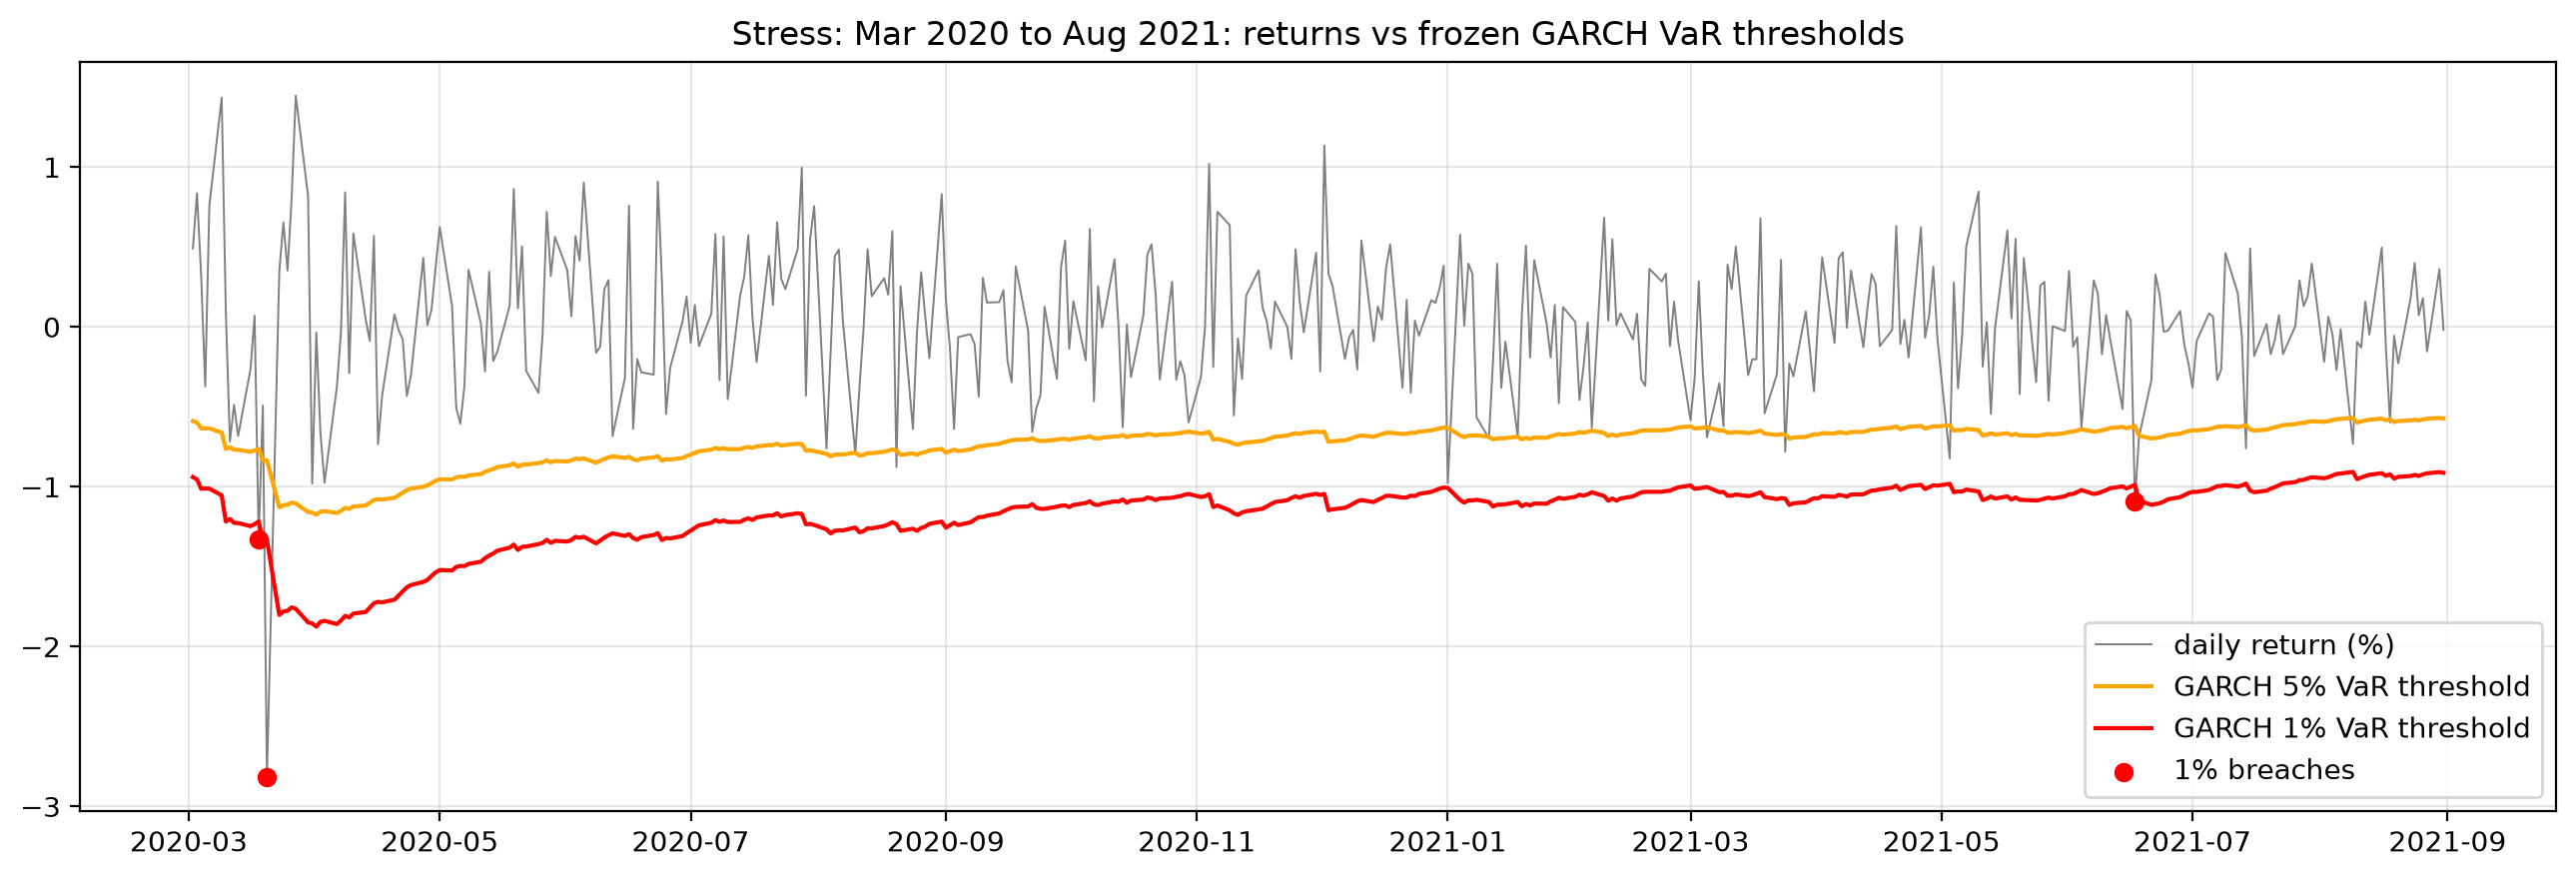

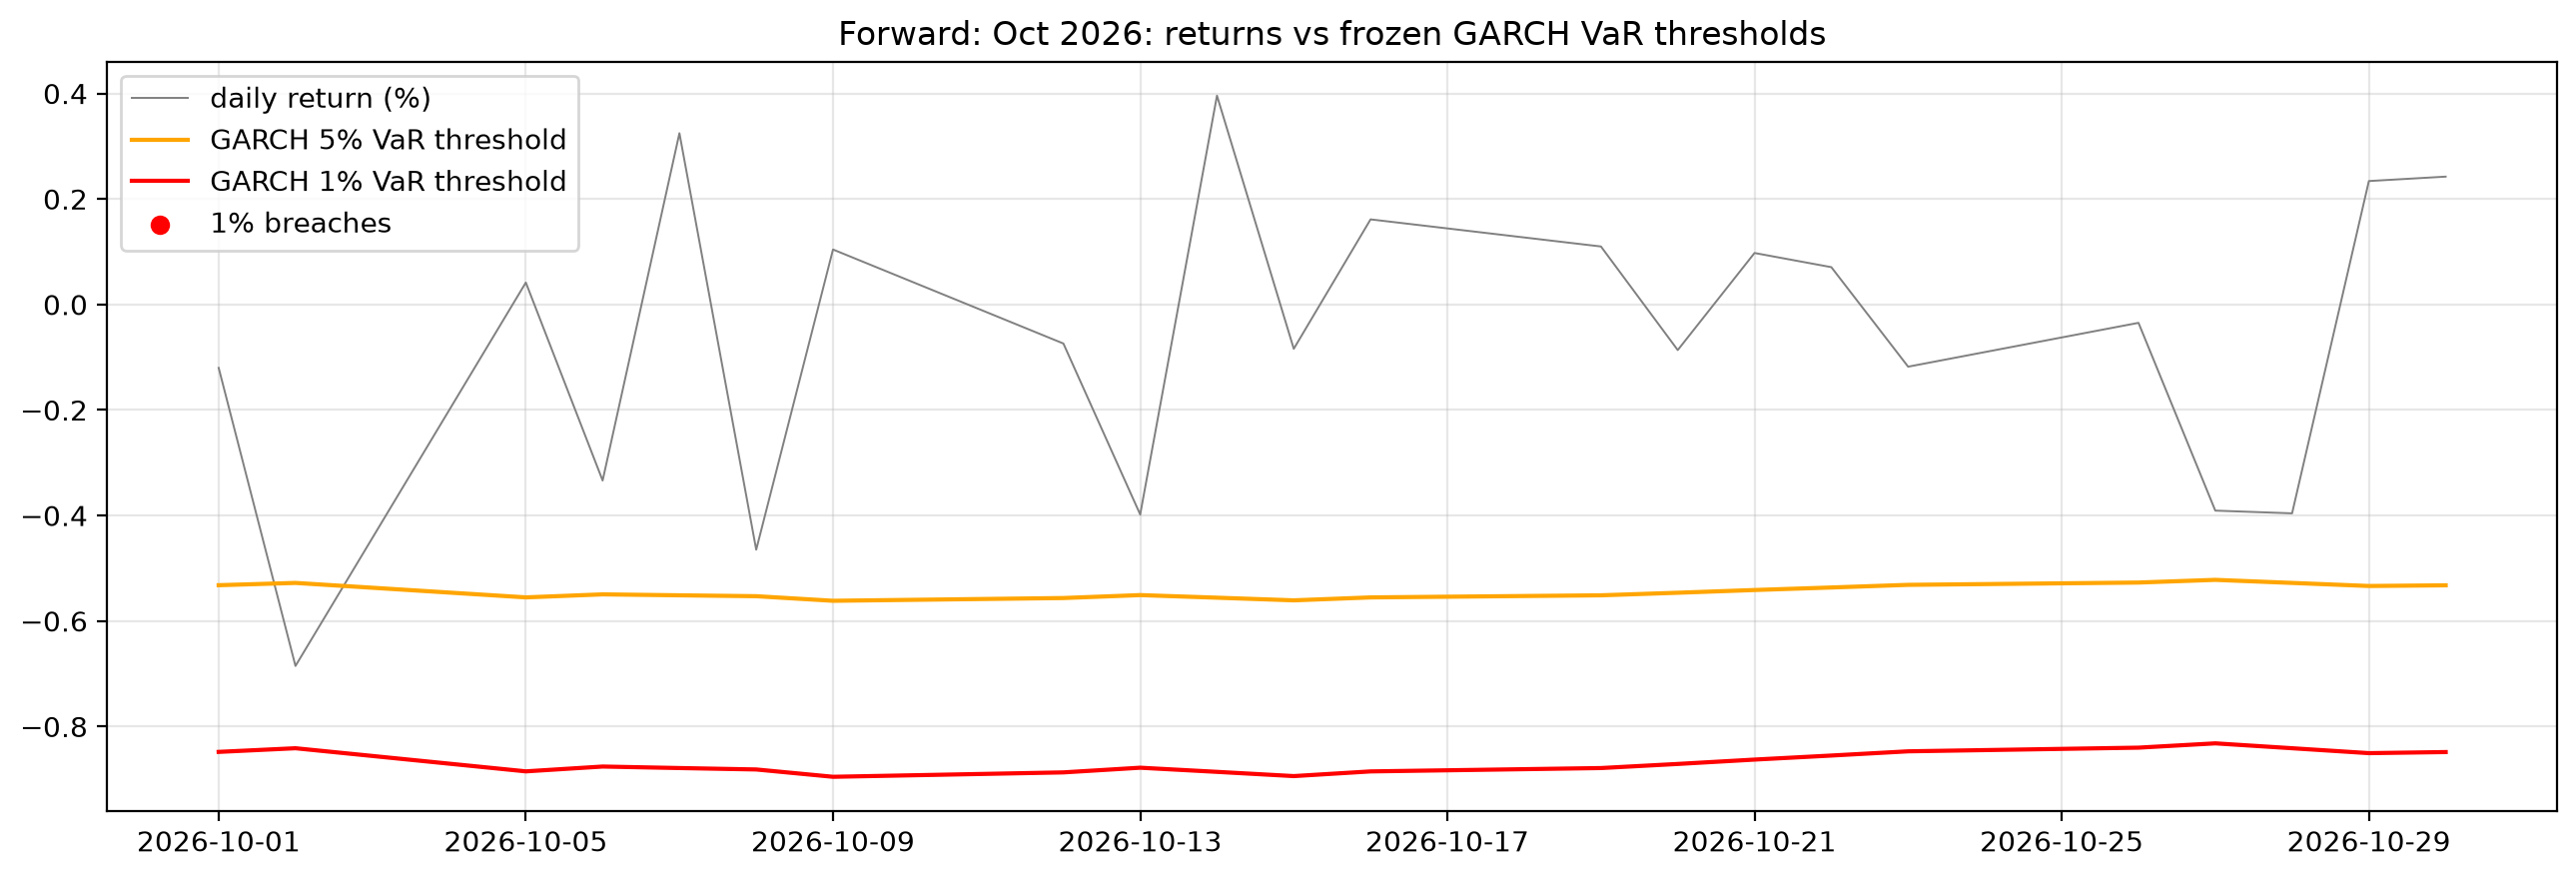

In [15]:
from IPython.display import Image, display
display(Image(filename="stress_window.png"))
display(Image(filename="forward_window.png"))

# *vii. Benchmark / Challenger Model*
Alternatives considered: The developer compared GARCH(1,1) with Student t innovations against Normal innovations, constant training volatility, and EWMA with a decay of 0.94, and used historical simulation as a cross-check of the VaR level. Normal innovations were rejected (Jarque-Bera p-value below 0.001; BIC of 1,470 versus 1,432).

Challenger: EWMA (decay of 0.94) with the same Student t quantile as GARCH was run on the developer’s test window and on the two independent windows, using the same data and metrics. The developer’s original comparison applied Normal quantiles to the benchmarks. Using a common quantile changed one 5% breach count and yielded no further conclusions.

Comparison: Both dynamic models clearly outperformed constant volatility. The challenger matched or outperformed GARCH on every volatility accuracy metric and was equally or better calibrated in every VaR comparison except the 22-day October window at 1%, where GARCH had the higher Kupiec p-value (a one-exception difference). This includes the 1% test window, where GARCH’s zero exceptions were rejected as too few. The results support using a dynamic volatility model but do not show GARCH(1,1) outperforming a simpler EWMA. GARCH’s remaining advantages are mean reversion toward a long-run level and its multi-day path simulation, which were not backtested here.

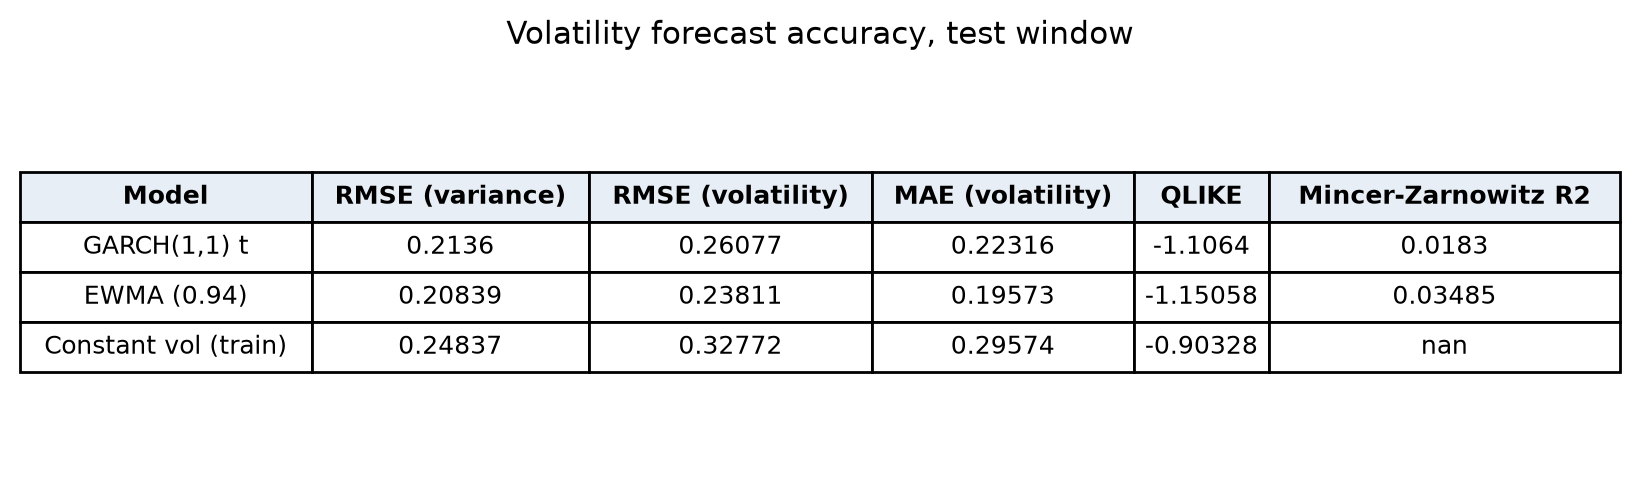

In [16]:
display(Image(filename="figures/oos_volatility_accuracy.png"))

#### Lower is better for all metrics except for R^2, “nan” for constant volatility means the regression is undefined with a constant forecast

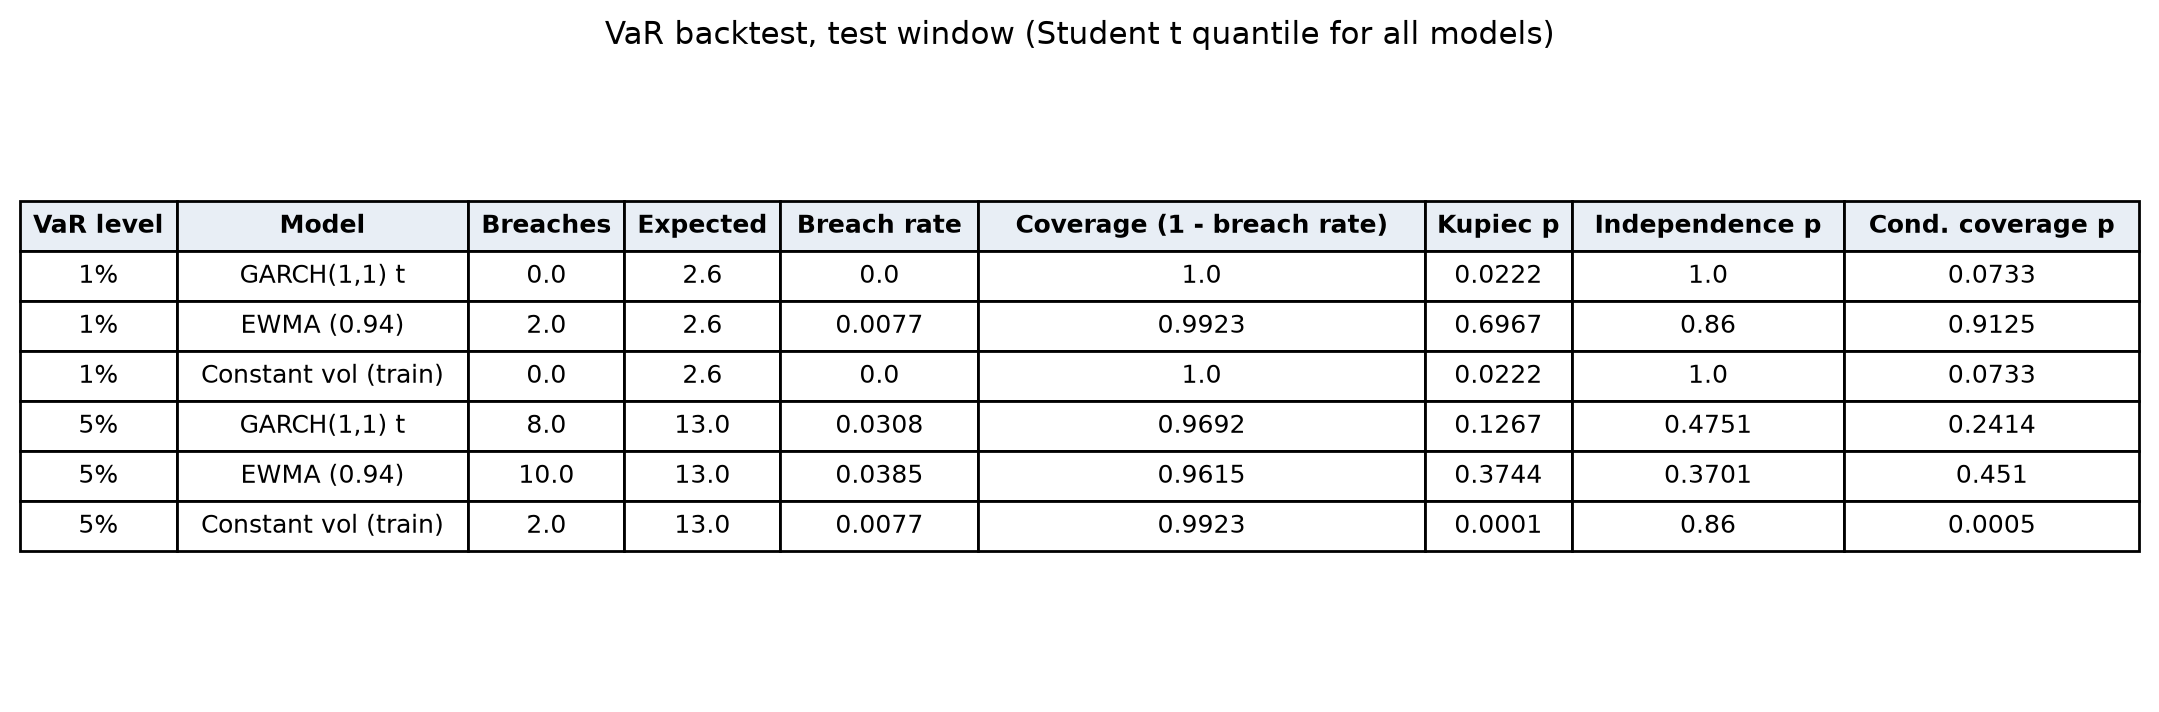

In [17]:
display(Image(filename="figures/backtest_test_window.png"))

# *viii. Limitations Review*
### Developer Section
### Model Limitations
1. **Model Parameter Sensitivity:** GARCH parameters are highly sensitive to extreme regime shifts (e.g., sudden financial crises or unexpected central bank rate decisions).
2. **Distributional Misspecification:** If standard normal distributions are assumed for innovations $z_t$, extreme tail events may still be underestimated compared to Student's $t$ or skewed distributions.
3. **Single Asset Focus:** Does not account for dynamic correlations with other currency pairs or cross-asset feedback loops.

#### Validator Response
These limitations are valid, but incomplete. Undisclosed limitations identified are: the position is long EUR only, with direction and notional undocumented (F10); VaR depends heavily on the current volatility forecast, and thresholds widened only after the first large loss in March 2020; validation evidence is limited (five years of data, a calm developer test window, short independent windows); the model tended to be conservative in calm periods, and its added complexity over EWMA was not demonstrated (F4).

# *ix. Ongoing Monitoring Review*
### Developer Section
### Ongoing Monitoring & Governance
* **Daily Backtesting (Kupiec POF Test):** Compare actual EOD daily portfolio returns against predicted VaR levels. If the number of exceptions exceeds regulatory limits (e.g., >2.5% for 97.5% VaR), trigger model recalibration.
* **Stress Testing & Scenario Analysis:** Supplement VaR metrics with historical stress tests (e.g., 2008 global financial crisis shock, post-pandemic inflation spikes) to account for tail-risk breaks.
* **Periodic Parameter Re-estimation:** Re-fit GARCH parameters monthly or quarterly to ensure parameters adapt to changing volatility regimes.

#### Validator Response
The proposed monitoring metrics are appropriate, but they lack clear trigger levels that would prompt a review. The plan also does not cover data quality checks, residual and persistence diagnostics, or comparison with a benchmark. These missing items are lighter weight and can be added as checklist items. The backtesting trigger refers to a 97.5% VaR, which the model does not produce, and acts only on too many exceptions.

# *x. Findings*

| Rating | Meaning | Example |
|---|---|---|
| High | Results cannot be trusted or reproduced | Code does not run; data leakage |
| Medium | Usable, but a real weakness | Untested assumption; documentation does not match code |
| Low | Documentation or presentation issue | Wrong date; unclear wording |

| ID | Section | Finding | Evidence (cell, number or test) | Rating | Required action |
|---|---|---|---|---|---|
| F1 | iii|The documentation states a data horizon of January 2021 to September 2026, but the data was collected from September 21, 2021 to September 18, 2026.| Cells [1,3] | Low | Correct model documentation to reflect dates of data collection |
| F2 | ii | 95% VaR is listed as an intended metric but is not computed in the Monte Carlo simulation. | Cells [34,35] | Medium | Compute 95% VaR in the simulation or remove it from the documentation |
| F3 | ii | The claim of supporting FRTB compliance is overstated. Business Context; U.S. agencies' March 2026 proposed rule is based on expected shortfall above the 97.5 percentile; model reports 1 day VaR at 95% and 99% | Cell [1] | Medium | Remove or qualify the claim |
| F4 | vii| EWMA with no estimated parameters matched or beat GARCH on accuracy and was equally or better calibrated; GARCH was conservative in calm periods | Cell [37] in Validator's Independent Testing Section | Medium | Document why GARCH was preferred over EWMA, or adopt EWMA |
| F5 | vi | Benchmarks used Normal quantiles while GARCH used Student t | Cell [30] | Low | Use a common quantile in the comparison |
| F6 | v | Package versions are not stated | Cell [1] | Low | State package versions |
| F7 | ix | Trigger levels are not specified within the Ongoing Monitoring & Governance section. The backtesting trigger refers to a 97.5% VaR, which the model does not produce, and acts only on too many exceptions. | Cell [1] | Medium | Restate triggers for 95% and 99% with explicit thresholds and responses |
| F8 | ix |Ongoing Model & Governance does not mention topics such as data quality checks, residual and persistence diagnostics, and comparison with a benchmark | Cell [1]|Low |Mention these topics in Ongoing Model & Governance section |
| F9 | iv, viii | Distributional limitation refers to Normal, which was not selected | Cell [1] | Low | Revise the limitation to address the chosen Student t distribution |
|F10| ii, iii| The position is long EUR only, and its direction and notional are undocumented| Cell [1]|Low| Mention position in documentation|

#### Cells referred to in this table are enumerated according to the "GARCH_Monte_Carlo_Validator.ipynb" file. Cell [1] refers to the Model Documentation, which does not have a cell number attached to it (as it is a markdown cell); it is referred to as Cell [1].

# *xi. Overall Conclusion*

#### Approved with conditions
This Value at Risk model estimates 1-day VaR and expected shortfall for a EUR/USD spot position by fitting a GARCH(1,1) volatility model with Student t shocks and simulating 100,000 Monte Carlo outcomes. The model was replicated without differences, no data leakage was found, and independent testing on a stress window (March 2020 to August 2021) and a forward window (October 2026) found exception counts consistent with the stated confidence levels, so the model is approved with conditions. Conditions: F2, F3, F4, and F7 must be resolved or formally accepted before the model is relied on.

#### *xii. Developer Response*
*Completed by the model developer*

| ID | Agree / Dispute | Response or action taken | Date |
|---|---|---|---|
| F1 | | | |
| F2 | | | |
| F3 | | | |
| F4 | | | |
| F5 | | | |
| F6 | | | |
| F7 | | | |
| F8 | | | |
| F9 | | | |
| F10 | | | |
**Validator sign-off:** (for each finding, state whether it is closed, accepted with conditions, or still open)